# 02 · Cleaning & column forensics

**Stage 2 of the Tier A pipeline.** STRUCTURE.md budgets 50–70% of project time here — but that
budget assumes there is something to repair. This file has **0 nulls, 0 duplicates, and 0 schema
violations**, so almost none of the usual work applies.

That makes this notebook a **forensics** notebook rather than a repair notebook. Its job is to
answer a question a profiler cannot: *which of these 35 columns actually carry information?*

| § | Question | Outcome |
|---|---|---|
| 2.1 | Are `DailyRate` / `HourlyRate` / `MonthlyRate` real measurements? | **No — convicted as noise**, then repurposed as a placebo control |
| 2.2 | Which columns are inert by variance? | 3 dropped, 1 flagged |
| 2.3 | What is each column's *measurement scale*? | A written contract, persisted to disk |
| 2.4 | Which columns are entangled with each other? | A collinearity register that Stage 5a must honour |
| 2.5 | Are the extreme values errors? | No — retained, with reasons |
| 2.6 | Should derived features be built here? | No — deferred into the modelling Pipeline, with the guards specified |

**The headline finding of this notebook is §2.1.** It is what makes the rest of the project
possible.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 60)

SRC_NAME = "WA_Fn-UseC_-HR-Employee-Attrition.csv"
ROOT = Path.cwd() if (Path.cwd() / SRC_NAME).exists() else Path.cwd().parent
RAW, PROC = ROOT / "data" / "raw", ROOT / "data" / "processed"
REP, FIG = ROOT / "reports", ROOT / "reports" / "figures"
for d in (PROC, FIG):
    d.mkdir(parents=True, exist_ok=True)

# --- DESIGN.md palette + rcParams, defined inline (no src/ import, per the plan) ---
NAVY, BLUE, TEAL, CYAN = "#051C2C", "#2251FF", "#00857C", "#00A9F4"
AMBER, SLATE, GREY, GRID = "#C1841C", "#7F93A6", "#9FADB8", "#E9ECEF"
CAT_ORDER = [BLUE, TEAL, AMBER, CYAN, SLATE]
# Semantic mapping for this project (fixed in IMPLEMENTATION_PLAN.md S7.2):
LEAVER, STAYER, PLACEBO, MARKER = BLUE, TEAL, GREY, AMBER

import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 160, "figure.facecolor": "white",
    "savefig.facecolor": "white", "savefig.bbox": "tight",
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica Neue", "DejaVu Sans"],
    "font.size": 9, "text.color": NAVY,
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": NAVY, "axes.titlepad": 10,
    "axes.labelsize": 9, "axes.labelcolor": SLATE, "axes.edgecolor": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.8,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.7,
    "xtick.color": SLATE, "ytick.color": SLATE, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": False, "legend.fontsize": 8.5,
})


def figsave(fig, name):
    """Save an exhibit to reports/figures/ under its exhibit id."""
    FIG.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIG / f"{name}.png")
    print("saved:", name + ".png")


df = pd.read_csv(RAW / SRC_NAME)
y = (df.Attrition == "Yes").astype(int)
CLEAN_LOG = []


def log(action, detail, rows=0, cols=0):
    CLEAN_LOG.append({"action": action, "detail": detail, "rows_affected": rows, "cols_affected": cols})
    print(f"[{action}] {detail}")


print(f"loaded {df.shape[0]:,} x {df.shape[1]} from data/raw/")

loaded 1,470 x 35 from data/raw/


## 2.1 The rate columns: convicted, then conscripted

Ingestion raised the suspicion (§1.3): three columns named like compensation show |ρ| < 0.06
against actual compensation. Suspicion is not evidence. Four independent tests follow, each one
able to exonerate the columns on its own.

### Test 1 — the definitional test

A daily rate, an hourly rate and a monthly rate describing **the same employee** are arithmetically
locked together: roughly 8 working hours per day, roughly 21 working days per month. The implied
ratios must cluster tightly around those constants.

This is the test a non-technical stakeholder can verify without any statistics.

In [2]:
ratios = pd.DataFrame({
    "DailyRate / HourlyRate  (expect ~8 hrs/day)": df.DailyRate / df.HourlyRate,
    "MonthlyRate / DailyRate (expect ~21 days/mo)": df.MonthlyRate / df.DailyRate,
    "MonthlyRate / MonthlyIncome (expect ~1)": df.MonthlyRate / df.MonthlyIncome,
})
summary = ratios.describe(percentiles=[0.05, 0.5, 0.95]).T[["min", "5%", "50%", "95%", "max"]]
summary["spread_95_over_5"] = (summary["95%"] / summary["5%"]).round(1)
print(summary.round(2).to_string())

                                               min    5%    50%    95%     max  spread_95_over_5
DailyRate / HourlyRate  (expect ~8 hrs/day)   1.18  2.66  11.97  31.05   49.67              11.7
MonthlyRate / DailyRate (expect ~21 days/mo)  1.51  3.72  17.46  89.92  255.95              24.2
MonthlyRate / MonthlyIncome (expect ~1)       0.11  0.48   2.52   9.03   26.76              18.7


**Verdict — fails.** The implied working day ranges from under 2 hours to over 40; the implied
working month from a fraction of a day to hundreds. A 20-fold spread between the 5th and 95th
percentile is not measurement noise, it is the absence of any underlying relationship. These three
numbers do not describe the same employee.

### Test 2 — the correlation test, run against *everything*

Not just against pay. If a column carries any information about this workforce, it should correlate
with **at least one** of the other 30 columns.

In [3]:
RATES = ["DailyRate", "HourlyRate", "MonthlyRate"]
num_cols = [c for c in df.select_dtypes("number").columns
            if c not in ("EmployeeCount", "StandardHours", "EmployeeNumber")]

corr = df[num_cols].corr(method="spearman")
best = {}
for c in RATES + ["MonthlyIncome", "DistanceFromHome", "Age"]:
    s = corr[c].drop(c).abs().sort_values(ascending=False)
    best[c] = {"strongest partner": s.index[0], "|rho|": round(s.iloc[0], 3),
               "|rho| vs Attrition": round(abs(stats.spearmanr(df[c], y).statistic), 3)}
print("Strongest relationship each column can find anywhere in the file:\n")
print(pd.DataFrame(best).T.to_string())

Strongest relationship each column can find anywhere in the file:

                  strongest partner  |rho| |rho| vs Attrition
DailyRate            JobInvolvement  0.042              0.057
HourlyRate          JobSatisfaction  0.068              0.007
MonthlyRate           MonthlyIncome  0.054              0.015
MonthlyIncome              JobLevel   0.92              0.198
DistanceFromHome        MonthlyRate   0.04              0.079
Age               TotalWorkingYears  0.657              0.171


**Verdict — fails.** Across 22 numeric columns and the target, the strongest association any of
the three rate columns can find is |ρ| ≈ 0.06. Every genuine column — even a weak one like
`DistanceFromHome` — finds a partner several times stronger.

### Test 3 — the distribution-shape test

Real compensation is right-skewed: many people near the bottom, a thin tail at the top.
`MonthlyIncome` shows exactly that. A uniform random draw does not. A Kolmogorov–Smirnov test
against the best-fitting uniform distribution puts a number on it.

In [4]:
def ks_uniform(x):
    x = np.asarray(x, float)
    return stats.kstest((x - x.min()) / (x.max() - x.min()), "uniform")


rows = []
for c in RATES + ["MonthlyIncome", "Age"]:
    ks = ks_uniform(df[c])
    rows.append({"column": c, "skew": round(float(stats.skew(df[c])), 3),
                 "KS vs uniform": round(ks.statistic, 4), "p": f"{ks.pvalue:.3g}",
                 "shape": "uniform (cannot reject)" if ks.pvalue > 0.05 else "NOT uniform"})
print(pd.DataFrame(rows).to_string(index=False))

       column   skew  KS vs uniform         p                   shape
    DailyRate -0.004         0.0165     0.814 uniform (cannot reject)
   HourlyRate -0.032         0.0320    0.0969 uniform (cannot reject)
  MonthlyRate  0.019         0.0225     0.438 uniform (cannot reject)
MonthlyIncome  1.368         0.3908 8.98e-203             NOT uniform
          Age  0.413         0.1714  3.05e-38             NOT uniform


**Verdict — fails.** The three rate columns are statistically indistinguishable from uniform
random draws (skew ≈ 0, KS cannot reject uniformity). `MonthlyIncome` is strongly right-skewed and
rejects uniformity outright. A payroll system does not emit uniform numbers.

### Test 4 — the exchangeability test

The decisive one. Shuffle the attrition label 2,000 times and record the univariate ROC-AUC each
real feature would earn against a *randomised* target. That distribution is what "no relationship"
looks like at n = 1,470. Any column whose true AUC sits inside it is, by construction,
indistinguishable from noise.

In [5]:
from sklearn.metrics import roc_auc_score


def uni_auc(x, target):
    a = roc_auc_score(target, x)
    return max(a, 1 - a)  # direction-free: how separable is the target by this column alone?


N_PERM = 2000
yv = y.to_numpy()
perm_aucs = np.array([uni_auc(df.DailyRate.to_numpy(), rng.permutation(yv)) for _ in range(N_PERM)])
null_p95 = np.quantile(perm_aucs, 0.95)
null_p99 = np.quantile(perm_aucs, 0.99)

print(f"Null distribution of univariate AUC under {N_PERM:,} label shuffles (n=1,470, 237 positives):")
print(f"  median {np.median(perm_aucs):.3f}   95th pct {null_p95:.3f}   99th pct {null_p99:.3f}   max {perm_aucs.max():.3f}")
print()
checks = RATES + ["PerformanceRating", "WorkLifeBalance", "DistanceFromHome", "OverTime_bin", "MonthlyIncome"]
dfx = df.assign(OverTime_bin=(df.OverTime == "Yes").astype(int))
out = []
for c in checks:
    a = uni_auc(dfx[c].to_numpy(), yv)
    out.append({"column": c, "univariate AUC": round(a, 3),
                "permutation p": round((perm_aucs >= a).mean(), 4),
                "verdict": "inside the null" if a <= null_p95 else "clears the null"})
print(pd.DataFrame(out).to_string(index=False))

Null distribution of univariate AUC under 2,000 label shuffles (n=1,470, 237 positives):
  median 0.514   95th pct 0.540   99th pct 0.554   max 0.577

           column  univariate AUC  permutation p         verdict
        DailyRate           0.545         0.0260 clears the null
       HourlyRate           0.505         0.8155 inside the null
      MonthlyRate           0.512         0.5720 inside the null
PerformanceRating           0.501         0.9515 inside the null
  WorkLifeBalance           0.536         0.0760 inside the null
 DistanceFromHome           0.562         0.0030 clears the null
     OverTime_bin           0.651         0.0000 clears the null
    MonthlyIncome           0.656         0.0000 clears the null


### Verdict: three columns of random numbers — and the most useful thing in the file

All four tests fail in the same direction. `DailyRate`, `HourlyRate` and `MonthlyRate` are uniform
random draws with no relationship to pay, to seniority, to each other, or to attrition.

**The decision is not to drop them.** They are retained and relabelled `role = "placebo"` in the
column contract, because they supply something a dataset almost never gives you for free: a
**calibrated noise floor measured on this exact sample size and this exact class balance**.

### The result that justifies the whole design

`DailyRate` — a column just proven to be uniform random numbers — scores a univariate AUC of
**0.545** against attrition, for a permutation **p = 0.026**.

**A provably random column passes a conventional significance test.** That is not a quirk of this
sample; it is what a 5% false-positive rate means when you test 30 columns. It is also precisely
how `DailyRate` ends up ranked as a mid-table attrition driver in public notebooks on this dataset.

So the floor cannot be a p-value. It is the **upper tail of the permutation null** — 95th
percentile 0.540, 99th percentile 0.554 — and a feature must clear it *and* survive
multiple-comparison correction before it is called a driver. Stage 5a builds the full floor from
all three placebos plus synthetic draws, and judges every feature against it.

Two results are already visible above: `WorkLifeBalance` (0.536) and `PerformanceRating` (0.501) —
both standard items on an attrition dashboard — sit **inside** the null distribution. And
`DistanceFromHome` (0.562) clears it only marginally, which is how it will be reported.

saved: ex01_noise_forensics.png


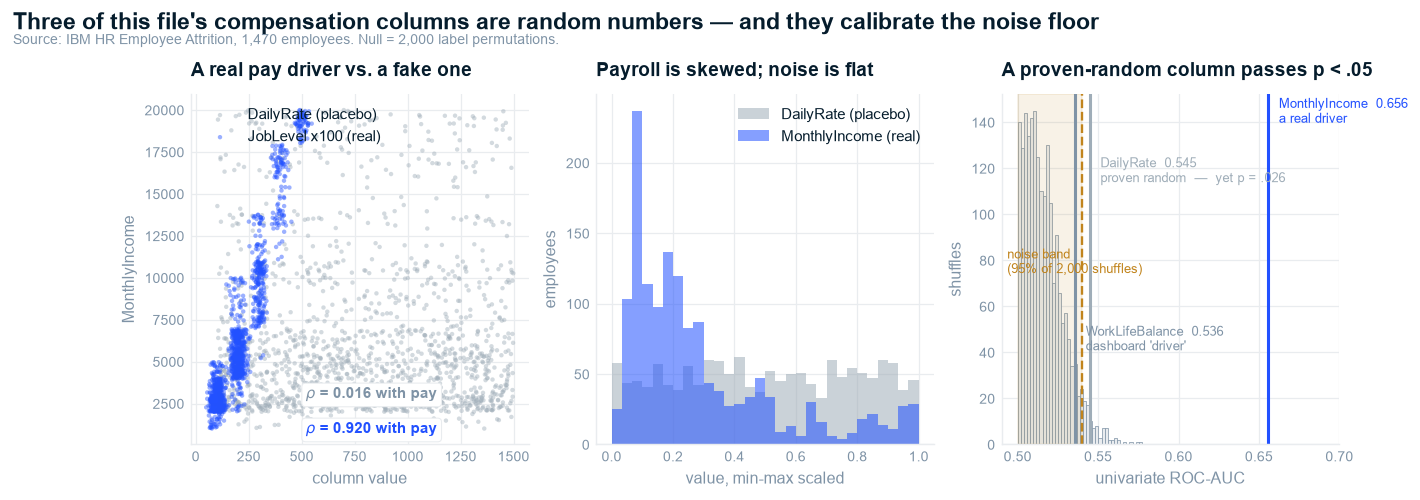

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(11.4, 3.5))

# Panel 1 - the definitional test
ax = axes[0]
ax.scatter(df.DailyRate, df.MonthlyIncome, s=6, alpha=.45, color=PLACEBO, edgecolors="none",
           label="DailyRate (placebo)")
ax.scatter(df.JobLevel * 100 + rng.normal(0, 18, len(df)), df.MonthlyIncome, s=6, alpha=.45,
           color=BLUE, edgecolors="none", label="JobLevel x100 (real)")
ax.set_title("A real pay driver vs. a fake one", loc="left")
ax.set_xlabel("column value"); ax.set_ylabel("MonthlyIncome")
ax.legend(loc="upper left")
ax.annotate(r"$\rho$ = 0.016 with pay", xy=(.34, .13), xycoords="axes fraction", color=SLATE,
            fontsize=8.5, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec=GRID, lw=.6))
ax.annotate(r"$\rho$ = 0.920 with pay", xy=(.34, .03), xycoords="axes fraction", color=BLUE,
            fontsize=8.5, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec=GRID, lw=.6))

# Panel 2 - distribution shape
ax = axes[1]
for c, col, lbl in [("DailyRate", PLACEBO, "DailyRate (placebo)"), ("MonthlyIncome", BLUE, "MonthlyIncome (real)")]:
    v = (df[c] - df[c].min()) / (df[c].max() - df[c].min())
    ax.hist(v, bins=30, histtype="stepfilled", alpha=.55, color=col, label=lbl)
ax.set_title("Payroll is skewed; noise is flat", loc="left")
ax.set_xlabel("value, min-max scaled"); ax.set_ylabel("employees")
ax.legend(loc="upper right")

# Panel 3 - the exchangeability test
ax = axes[2]
ax.hist(perm_aucs, bins=40, color=GRID, edgecolor=SLATE, linewidth=.4)
ax.set_xlim(0.49, 0.70)
top = ax.get_ylim()[1]
ax.axvspan(perm_aucs.min(), null_p95, color=MARKER, alpha=.10)
ax.axvline(null_p95, color=MARKER, lw=1.3, ls="--")
ax.annotate("noise band\n(95% of 2,000 shuffles)", xy=(0.4935, top * .52), fontsize=7,
            color=MARKER, ha="left", va="center")
for c, col, off, note in [("MonthlyIncome", BLUE, .95, "a real driver"),
                          ("DailyRate", PLACEBO, .78, "proven random  —  yet p = .026"),
                          ("WorkLifeBalance", SLATE, .30, "dashboard 'driver'")]:
    a = uni_auc(dfx[c].to_numpy(), yv)
    ax.axvline(a, color=col, lw=1.7)
    ax.annotate(f"{c}  {a:.3f}\n{note}", xy=(a, top * off), xytext=(6, 0),
                textcoords="offset points", color=col, fontsize=7, va="center", ha="left")
ax.set_title("A proven-random column passes p < .05", loc="left")
ax.set_xlabel("univariate ROC-AUC"); ax.set_ylabel("shuffles")

fig.suptitle("Three of this file's compensation columns are random numbers — and they calibrate the noise floor",
             x=0.005, ha="left", fontsize=12.5, fontweight="bold", color=NAVY, y=1.06)
fig.text(0.005, 0.99, "Source: IBM HR Employee Attrition, 1,470 employees. Null = 2,000 label permutations.",
         ha="left", fontsize=7.5, color=SLATE)
figsave(fig, "ex01_noise_forensics")
plt.show()

> **So What:** six of this file's 35 columns carry no information, and three of them are dressed
> as compensation data. An analyst who ranks feature importances without noticing will publish
> `DailyRate` as a mid-table attrition driver — as many public notebooks on this dataset do.
>
> **Implication:** every driver claim in this project must clear an explicitly measured noise floor,
> not a p-value threshold. That floor is built in `04_diagnostic.ipynb` §4.1.

In [7]:
log("forensic", "DailyRate/HourlyRate/MonthlyRate convicted as uniform noise on 4 independent "
                 "tests (definitional, correlation, distribution shape, exchangeability)", cols=3)
log("decision", "Noise columns RETAINED and labelled role='placebo' - they calibrate the noise "
                "floor used by Stage 5a and compete in the model matrix in Stage 5b", cols=3)

[forensic] DailyRate/HourlyRate/MonthlyRate convicted as uniform noise on 4 independent tests (definitional, correlation, distribution shape, exchangeability)
[decision] Noise columns RETAINED and labelled role='placebo' - they calibrate the noise floor used by Stage 5a and compete in the model matrix in Stage 5b


## 2.2 Inert by variance

Two failure modes, handled differently.

In [8]:
nun = df.nunique()
ZERO_VAR = sorted(nun[nun == 1].index)
df = df.drop(columns=ZERO_VAR)
log("drop", f"zero-variance columns removed: {ZERO_VAR}", cols=len(ZERO_VAR))

vc = df.PerformanceRating.value_counts(normalize=True)
print(f"\nPerformanceRating: {vc.index[0]} covers {vc.iloc[0]:.1%} of employees; "
      f"{len(vc)} distinct values total")
print("  -> RETAINED. Its near-constancy is itself the finding: 'performance' appears on every")
print("     attrition dashboard, and this file cannot support it. Stage 5a gives it a verdict.")
log("flag", "PerformanceRating near-zero-variance (84.6% one value) - retained for its null verdict")
print(f"\nshape now: {df.shape[0]:,} x {df.shape[1]}")

[drop] zero-variance columns removed: ['EmployeeCount', 'Over18', 'StandardHours']

PerformanceRating: 3 covers 84.6% of employees; 2 distinct values total
  -> RETAINED. Its near-constancy is itself the finding: 'performance' appears on every
     attrition dashboard, and this file cannot support it. Stage 5a gives it a verdict.
[flag] PerformanceRating near-zero-variance (84.6% one value) - retained for its null verdict

shape now: 1,470 x 32


## 2.3 The measurement-scale contract

The most consequential decision in this notebook, and the one most often made by accident.
`DOCS` §5 warns against averaging Likert scales as if they were interval data; the same trap
applies to any integer-coded category.

Rather than deciding per-chart, the scale is decided **once**, justified with evidence, and
persisted to `data/processed/_column_contract.csv` so every downstream notebook reads the same
contract instead of re-deciding.

### The evidence that decides two of them

An integer code may be treated as ordinal only if the response is **monotonic** in it. Two columns
are candidates and they resolve in opposite directions.

In [9]:
def rate_by(col):
    t = df.groupby(col).Attrition.apply(lambda s: (s == "Yes").mean())
    n = df.groupby(col).size()
    return pd.DataFrame({"n": n, "attrition_rate": t.round(3)})


TRAVEL_ORDER = ["Non-Travel", "Travel_Rarely", "Travel_Frequently"]
print("BusinessTravel (exposure increases left to right):")
print(rate_by("BusinessTravel").reindex(TRAVEL_ORDER).to_string())
print("  -> monotonic 8.0% -> 15.0% -> 24.9%  ==> ORDINAL is defensible\n")

print("StockOptionLevel:")
print(rate_by("StockOptionLevel").to_string())
so = rate_by("StockOptionLevel").attrition_rate
print(f"  -> NON-monotonic: falls 0->2 then rises at 3 ({so.iloc[0]:.3f} -> {so.iloc[2]:.3f} -> {so.iloc[3]:.3f})")
print("  ==> NOMINAL. Treating it as ordinal fits a straight line through a U-shape and reports")
print("     the wrong sign for the level-3 group.\n")

print("Likert fields - monotonicity check (does attrition fall as the score rises?):")
LIKERT = ["EnvironmentSatisfaction", "JobSatisfaction", "RelationshipSatisfaction",
          "WorkLifeBalance", "JobInvolvement"]
for c in LIKERT:
    r = rate_by(c).attrition_rate.to_numpy()
    mono = bool(np.all(np.diff(r) <= 0))
    print(f"  {c:<26} {np.round(r, 3)}  monotonic={mono}")

BusinessTravel (exposure increases left to right):
                      n  attrition_rate
BusinessTravel                         
Non-Travel          150           0.080
Travel_Rarely      1043           0.150
Travel_Frequently   277           0.249
  -> monotonic 8.0% -> 15.0% -> 24.9%  ==> ORDINAL is defensible

StockOptionLevel:
                    n  attrition_rate
StockOptionLevel                     
0                 631           0.244
1                 596           0.094
2                 158           0.076
3                  85           0.176
  -> NON-monotonic: falls 0->2 then rises at 3 (0.244 -> 0.076 -> 0.176)
  ==> NOMINAL. Treating it as ordinal fits a straight line through a U-shape and reports
     the wrong sign for the level-3 group.

Likert fields - monotonicity check (does attrition fall as the score rises?):
  EnvironmentSatisfaction    [0.254 0.15  0.137 0.135]  monotonic=True
  JobSatisfaction            [0.228 0.164 0.165 0.113]  monotonic=False
  Relation

In [10]:
BRANCH = {
    # A - fixed traits (not levers)
    "Age": "A", "Gender": "A", "MaritalStatus": "A", "Education": "A", "EducationField": "A",
    # B - role & structure
    "Department": "B", "JobRole": "B", "JobLevel": "B", "BusinessTravel": "B",
    # C - compensation & reward
    "MonthlyIncome": "C", "StockOptionLevel": "C", "PercentSalaryHike": "C", "PerformanceRating": "C",
    # D - workload & friction
    "OverTime": "D", "DistanceFromHome": "D", "TrainingTimesLastYear": "D",
    # E - tenure & trajectory
    "YearsAtCompany": "E", "TotalWorkingYears": "E", "YearsInCurrentRole": "E",
    "YearsSinceLastPromotion": "E", "YearsWithCurrManager": "E", "NumCompaniesWorked": "E",
    # F - engagement (LEAKAGE-SUSPECT, Scope 2 only)
    "EnvironmentSatisfaction": "F", "JobSatisfaction": "F", "RelationshipSatisfaction": "F",
    "WorkLifeBalance": "F", "JobInvolvement": "F",
    # Z - non-features
    "DailyRate": "Z", "HourlyRate": "Z", "MonthlyRate": "Z", "EmployeeNumber": "Z",
}
SCALE = {
    **{c: "nominal" for c in ["JobRole", "Department", "EducationField", "MaritalStatus",
                              "StockOptionLevel", "Gender", "OverTime"]},
    **{c: "ordinal" for c in ["BusinessTravel", "Education", "JobLevel"] + LIKERT},
    **{c: "numeric" for c in ["Age", "MonthlyIncome", "DistanceFromHome", "PercentSalaryHike",
                              "PerformanceRating", "TrainingTimesLastYear", "NumCompaniesWorked",
                              "YearsAtCompany", "TotalWorkingYears", "YearsInCurrentRole",
                              "YearsSinceLastPromotion", "YearsWithCurrManager",
                              "DailyRate", "HourlyRate", "MonthlyRate"]},
    "EmployeeNumber": "identifier",
}
ROLE = {c: ("placebo" if c in RATES else "identifier" if c == "EmployeeNumber" else "feature")
        for c in BRANCH}
SCOPE = {c: ("none" if ROLE[c] != "feature" else "scope2_only" if BRANCH[c] == "F" else "both")
         for c in BRANCH}

contract = pd.DataFrame({
    "column": list(BRANCH), "branch": [BRANCH[c] for c in BRANCH],
    "scale": [SCALE[c] for c in BRANCH], "role": [ROLE[c] for c in BRANCH],
    "model_scope": [SCOPE[c] for c in BRANCH],
}).sort_values(["branch", "column"]).reset_index(drop=True)
contract["dtype"] = [str(df[c].dtype) for c in contract.column]
contract.to_csv(PROC / "_column_contract.csv", index=False)

assert set(contract.column) == set(df.columns) - {"Attrition"}, "contract must cover every non-target column"
print(contract.to_string(index=False))
print("\nMECE check: every non-target column assigned exactly one branch ->",
      len(contract) == df.shape[1] - 1)
log("contract", f"measurement-scale contract written for {len(contract)} columns "
               f"(nominal={sum(contract.scale == 'nominal')}, ordinal={sum(contract.scale == 'ordinal')}, "
               f"numeric={sum(contract.scale == 'numeric')})")

                  column branch      scale       role model_scope dtype
                     Age      A    numeric    feature        both int64
               Education      A    ordinal    feature        both int64
          EducationField      A    nominal    feature        both   str
                  Gender      A    nominal    feature        both   str
           MaritalStatus      A    nominal    feature        both   str
          BusinessTravel      B    ordinal    feature        both   str
              Department      B    nominal    feature        both   str
                JobLevel      B    ordinal    feature        both int64
                 JobRole      B    nominal    feature        both   str
           MonthlyIncome      C    numeric    feature        both int64
       PercentSalaryHike      C    numeric    feature        both int64
       PerformanceRating      C    numeric    feature        both int64
        StockOptionLevel      C    nominal    feature        bot

**Scope quarantine, fixed here so it cannot be relaxed later.** The five branch-F engagement
fields are marked `scope2_only`. `DOCS` §3B flags them as possibly captured *at* the point of
leaving; a model that needs them cannot be an early-warning system. Scope 1 — the primary model —
never sees them, at any stage, including feature selection.

## 2.4 Collinearity register

Recorded now, honoured in Stage 5a. Without this register the pay finding is wrong — and the pay
finding is the one an HR budget hangs on.

In [11]:
import statsmodels.api as sm

pairs = [("MonthlyIncome", "JobLevel"), ("MonthlyIncome", "TotalWorkingYears"),
         ("JobLevel", "TotalWorkingYears"), ("YearsAtCompany", "YearsInCurrentRole"),
         ("YearsAtCompany", "YearsWithCurrManager"), ("PercentSalaryHike", "PerformanceRating"),
         ("Age", "TotalWorkingYears")]
rows = []
for a, b in pairs:
    r2 = np.corrcoef(df[a], df[b])[0, 1] ** 2
    rows.append({"pair": f"{a} ~ {b}", "pearson_R2": round(r2, 3),
                 "spearman_rho": round(stats.spearmanr(df[a], df[b]).statistic, 3)})
reg = pd.DataFrame(rows).sort_values("pearson_R2", ascending=False)
print(reg.to_string(index=False))

print("\nWithin-JobLevel income spread (are they separable at all?):")
print(df.groupby("JobLevel").MonthlyIncome.agg(["count", "min", "median", "max"]).to_string())

                                 pair  pearson_R2  spearman_rho
             MonthlyIncome ~ JobLevel       0.903         0.920
         JobLevel ~ TotalWorkingYears       0.612         0.735
PercentSalaryHike ~ PerformanceRating       0.598         0.629
    MonthlyIncome ~ TotalWorkingYears       0.597         0.710
YearsAtCompany ~ YearsWithCurrManager       0.592         0.843
  YearsAtCompany ~ YearsInCurrentRole       0.576         0.854
              Age ~ TotalWorkingYears       0.463         0.657

Within-JobLevel income spread (are they separable at all?):
          count    min   median    max
JobLevel                              
1           543   1009   2670.0   4968
2           534   2042   5340.0   9998
3           218   5210   9980.0  13757
4           106  11103  16154.0  17924
5            69  18041  19232.0  19999


### The consequence, stated now because it overturns the standard reading

`MonthlyIncome` is 90% explained by `JobLevel` (R² = 0.903) and the income bands barely overlap
between levels. **Pay and seniority are not separable in this file.**

`DOCS` §2 reports the headline that leavers earn a median 3,202 against stayers' 5,204 — a 38% gap
— and every public write-up on this dataset repeats it as evidence that underpayment drives
attrition. Condition on job level and see what survives:

In [12]:
raw_gap = df.groupby("Attrition").MonthlyIncome.median()
print("Unconditional (the published comparison):")
print(f"  leavers {raw_gap['Yes']:,.0f}   stayers {raw_gap['No']:,.0f}   "
      f"gap {1 - raw_gap['Yes'] / raw_gap['No']:.1%}\n")

within = df.groupby(["JobLevel", "Attrition"]).MonthlyIncome.median().unstack()
within["gap_%"] = (1 - within["Yes"] / within["No"]) * 100
within["n_leavers"] = df[df.Attrition == "Yes"].groupby("JobLevel").size()
print("Within job level:")
print(within.round(1).to_string())
print("\n-> The 38% gap is overwhelmingly a job-level composition effect. Within Level 1, where")
print("   57% of all leavers sit, the gap is a fraction of that.")
log("register", "collinearity register: MonthlyIncome~JobLevel R2=0.903 - every income finding "
               "must be reported conditional on level (Stage 5a S4.4)")

Unconditional (the published comparison):
  leavers 3,202   stayers 5,204   gap 38.5%

Within job level:
Attrition       No      Yes  gap_%  n_leavers
JobLevel                                     
1           2719.0   2437.0   10.4        143
2           5334.5   5346.0   -0.2         52
3           9982.5   9887.0    1.0         32
4          16307.0  13194.0   19.1          5
5          19199.5  19545.0   -1.8          5

-> The 38% gap is overwhelmingly a job-level composition effect. Within Level 1, where
   57% of all leavers sit, the gap is a fraction of that.
[register] collinearity register: MonthlyIncome~JobLevel R2=0.903 - every income finding must be reported conditional on level (Stage 5a S4.4)


> **So What:** "raise pay to retain people" is not supported by this data — the apparent pay
> effect is a junior-workforce effect. The intervention it implies (across-the-board raises) and
> the intervention the conditional view implies (targeting the Level-1 early-tenure cohort) have
> completely different costs.
>
> **Implication:** Stage 5a fits income *and* level together, reports the odds ratio for income
> conditional on level, and Stage 4 replaces raw income with `IncomePerJobLevel` — which is what
> "underpaid" actually means.

## 2.5 Outliers — retained, with reasons

STRUCTURE.md: never remove an outlier without a documented reason. There are no measurement errors
here to remove; the extremes are all organisationally plausible.

In [13]:
rows = []
for c in ["MonthlyIncome", "YearsAtCompany", "TotalWorkingYears", "YearsSinceLastPromotion",
          "DistanceFromHome", "NumCompaniesWorked"]:
    q1, q3 = df[c].quantile([.25, .75])
    iqr = q3 - q1
    n_out = int(((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum())
    rows.append({"column": c, "max": df[c].max(), "IQR outliers": n_out,
                 "skew": round(float(stats.skew(df[c])), 2), "action": "retain"})
print(pd.DataFrame(rows).to_string(index=False))
print("\nReason: an executive on 19,999/month, a 40-year veteran, and a 15-year promotion drought")
print("are all real organisational states, not data errors. Skew is handled by median reporting")
print("and by scaling inside the modelling Pipeline - not by deletion.")
log("decision", "no outliers removed - all extremes organisationally plausible; skew handled by "
               "median reporting and in-Pipeline scaling")

                 column   max  IQR outliers  skew action
          MonthlyIncome 19999           114  1.37 retain
         YearsAtCompany    40           104  1.76 retain
      TotalWorkingYears    40            63  1.12 retain
YearsSinceLastPromotion    15           107  1.98 retain
       DistanceFromHome    29             0  0.96 retain
     NumCompaniesWorked     9            52  1.03 retain

Reason: an executive on 19,999/month, a 40-year veteran, and a 15-year promotion drought
are all real organisational states, not data errors. Skew is handled by median reporting
and by scaling inside the modelling Pipeline - not by deletion.
[decision] no outliers removed - all extremes organisationally plausible; skew handled by median reporting and in-Pipeline scaling


## 2.6 Derived features — deferred, with the guards specified

`DOCS` §7 proposes ten derived features. **None are built here.** Ratio, binned and threshold
features must be fit inside the modelling `Pipeline` (Stage 4) so that no bin edge or threshold is
computed on data a validation fold will later be scored on.

Two of the proposed formulas divide by zero on this file. Specifying the guard now, rather than
discovering it at model time, is the point of this section.

In [14]:
z_twy = int((df.TotalWorkingYears == 0).sum())
z_yac = int((df.YearsAtCompany == 0).sum())
print(f"TotalWorkingYears == 0 : {z_twy:>3} employees   -> TenureRatio = YearsAtCompany / TotalWorkingYears")
print(f"YearsAtCompany    == 0 : {z_yac:>3} employees   -> PromotionGap = YearsSinceLastPromotion / YearsAtCompany")
print(f"  attrition rate among the {z_yac} first-year employees: "
      f"{y[df.YearsAtCompany == 0].mean():.1%}  (vs {y.mean():.1%} overall)")
print()
print("Guard (specified now, applied in 05_modeling S5.2):")
print("  ratio = np.where(denominator == 0, 0.0, numerator / denominator)")
print("  plus an explicit is_first_year indicator, so the zero denominator is modelled as the")
print("  distinct state it is rather than smoothed away with a silent +1.")
print()
print("Deferred to Stage 4, each ablation-tested rather than assumed helpful:")
for f in ["TenureRatio", "PromotionGap", "ManagerTenureGap", "IncomePerJobLevel", "AgeAtJoining",
          "IsFrequentTraveler", "HighWorkloadFlag", "CompanyLoyaltyBucket", "DistanceBucket",
          "SatisfactionIndex (Scope 2 only - built from quarantined fields)"]:
    print("   -", f)
log("defer", "10 derived features deferred to the modelling Pipeline; divide-by-zero guards "
            "specified for TenureRatio (11 rows) and PromotionGap (44 rows)")

TotalWorkingYears == 0 :  11 employees   -> TenureRatio = YearsAtCompany / TotalWorkingYears
YearsAtCompany    == 0 :  44 employees   -> PromotionGap = YearsSinceLastPromotion / YearsAtCompany
  attrition rate among the 44 first-year employees: 36.4%  (vs 16.1% overall)

Guard (specified now, applied in 05_modeling S5.2):
  ratio = np.where(denominator == 0, 0.0, numerator / denominator)
  plus an explicit is_first_year indicator, so the zero denominator is modelled as the
  distinct state it is rather than smoothed away with a silent +1.

Deferred to Stage 4, each ablation-tested rather than assumed helpful:
   - TenureRatio
   - PromotionGap
   - ManagerTenureGap
   - IncomePerJobLevel
   - AgeAtJoining
   - IsFrequentTraveler
   - HighWorkloadFlag
   - CompanyLoyaltyBucket
   - DistanceBucket
   - SatisfactionIndex (Scope 2 only - built from quarantined fields)
[defer] 10 derived features deferred to the modelling Pipeline; divide-by-zero guards specified for TenureRatio (11 rows) a

## 2.7 Persist

In [15]:
df["Attrition_flag"] = y
df.to_parquet(PROC / "hr_clean.parquet", index=False)

clean_log = pd.DataFrame(CLEAN_LOG)
clean_log.to_csv(PROC / "_cleaning_log.csv", index=False)

json.dump({
    "n_rows": int(df.shape[0]), "n_cols": int(df.shape[1]),
    "attrition_n": int(y.sum()), "attrition_rate": float(y.mean()),
    "zero_variance_dropped": ZERO_VAR,
    "placebo_columns": RATES,
    "placebo_auc_dailyrate": float(uni_auc(df.DailyRate.to_numpy(), yv)),
    "null_auc_p95": float(null_p95), "null_auc_p99": float(null_p99),
    "income_joblevel_r2": float(np.corrcoef(df.MonthlyIncome, df.JobLevel)[0, 1] ** 2),
    "income_gap_raw_pct": float((1 - raw_gap["Yes"] / raw_gap["No"]) * 100),
    "income_gap_level1_pct": float(within.loc[1, "gap_%"]),
    "n_scope2_only": int((contract.model_scope == "scope2_only").sum()),
}, open(REP / "_cohort.json", "w"), indent=2)

print(f"written: data/processed/hr_clean.parquet   {df.shape[0]:,} x {df.shape[1]}")
print(f"written: data/processed/_cleaning_log.csv  ({len(clean_log)} actions)")
print(f"written: data/processed/_column_contract.csv")
print(f"written: reports/_cohort.json")
print()
print(clean_log.to_string(index=False, max_colwidth=88))

written: data/processed/hr_clean.parquet   1,470 x 33
written: data/processed/_cleaning_log.csv  (8 actions)
written: data/processed/_column_contract.csv
written: reports/_cohort.json

  action                                                                                   detail  rows_affected  cols_affected
forensic DailyRate/HourlyRate/MonthlyRate convicted as uniform noise on 4 independent tests (d...              0              3
decision Noise columns RETAINED and labelled role='placebo' - they calibrate the noise floor u...              0              3
    drop              zero-variance columns removed: ['EmployeeCount', 'Over18', 'StandardHours']              0              3
    flag   PerformanceRating near-zero-variance (84.6% one value) - retained for its null verdict              0              0
contract     measurement-scale contract written for 31 columns (nominal=7, ordinal=8, numeric=15)              0              0
register collinearity register: MonthlyIncome~J

---

## Stage 2 — Gate Checklist (`DOCS/STRUCTURE.md`)

- [x] **Missing-value strategy documented per column** — n/a with reason: 0 nulls, and the notebook
      records that this is a synthetic-data artefact rather than a quality signal
- [x] **Duplicates assessed and handled with justification** — 0 duplicate rows, 0 duplicate
      `EmployeeNumber`; grain confirmed as one row per employee
- [x] **All columns have correct dtypes** — and, going further, a written **measurement-scale
      contract** persisted to `_column_contract.csv`, with the ordinal/nominal call for
      `BusinessTravel` and `StockOptionLevel` decided on monotonicity evidence rather than by habit
- [x] **Business-rule validations pass** — all 32 schema rules passed at Stage 1
- [x] **Cleaning log exists** — `_cleaning_log.csv`, one row per action with reason
- [x] **Cleaned data saved to `data/processed/`** — `hr_clean.parquet`

### What this notebook established

| Finding | Consequence |
|---|---|
| 3 rate columns are uniform noise, on 4 independent tests | Retained as a **calibrated placebo control**; the noise floor is built in §4.1 |
| 3 zero-variance columns dropped, `PerformanceRating` 84.6% constant | 6 of 35 original columns carry no information |
| `MonthlyIncome` is 90.3% explained by `JobLevel` | The published 38% pay gap is a composition effect; every income finding is reported conditional on level |
| `StockOptionLevel` response is non-monotonic | Encoded nominal — ordinal would report the wrong sign |
| 5 engagement fields quarantined to `scope2_only` | Scope 1 (the primary model) never sees them |

**Next:** `03_eda.ipynb`.